# The model

Everything that defines the kinetic model of E. coli glycolysis (PTS to enolase) is read from one place, the package `src/model/`, plus the data in `Data/` and the run settings in `settings/*.csv`. This notebook shows each piece:

1. the 37 parameters and the 9 reactions (`model/parameters.py`);
2. the reaction groups and the rule *at least one free parameter per rate equation*;
3. the rate laws (`model/kinetics.py`), PTS plus the Noor et al. (2013) Eq. 35 form for the other 8 reactions;
4. the stoichiometry and the equilibrium constants (`model/stoichiometry.py`);
5. the estimation problem: what is measured, what is free per condition, the objective;
6. the data bounds of the per-condition variables and the check that they contain every measurement (`data.py`);
7. the settings CSV files that steer the whole pipeline.

Nothing here is computed in long runs, so the notebook has no `RUN` section.

In [1]:
import os
import sys
import logging
import warnings

HERE = os.getcwd()
REPO = os.path.dirname(HERE) if os.path.basename(HERE) == "notebooks" else HERE
for path in (os.path.join(REPO, "notebooks"), os.path.join(REPO, "src")):
    if path not in sys.path:
        sys.path.insert(0, path)

import settings  # noqa: F401  (pins BLAS / OpenMP to one thread before numpy is loaded)

warnings.filterwarnings("ignore")
logging.getLogger("pyomo").setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model.parameters import (ALL_PARAMS, PARAM_RXN_MAP, RXN_ORDER, BALANCED_KEYS, IMBALANCED_KEYS,
                              ENZYME_KEYS, FLUX_KEYS, LI_FLUX_KEYS, FREE_DRAIN_KEYS, LITERATURE_THETA, RXN_OF_PARAM,
                              reaction_groups)
from model.stoichiometry import build_stoichiometric_matrix, stoichiometric_table, load_keq
from model.kinetics import EcoliCarbonKinetics
from identifiability.rules import is_protected
from paths import SETTINGS_DIR
from settings import PROTECTED_PREFIXES, THETA_BOUNDS
from data import (variable_bounds, check_bounds_contain_data, load_data_frames, load_condition,
                  load_measurement_sigmas, available_conditions)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)

## 1. Parameters and reactions

Nine reactions in model order: PTS (glucose uptake), PGI, PFK, FBA, TPI, GAPDH, PGK, GPM and ENO. The model has 37 kinetic parameters in `ALL_PARAMS`: the PTS keeps its empirical form (5 parameters) and each of the 8 other reactions has one forward $k_\mathrm{cat}$ plus the half-saturation constants of its substrates ($K_s$) and products ($K_p$). Parameter names end with the reaction number (`Ks_g6p_1` style), except `Ks_g6p_pgi` and `Kp_f6p_pgi`, which carry the reaction name.

The bounds of every parameter live in `settings/theta_bounds.csv`: $K$ constants in $[10^{-3}, 20]$ mM, $k_\mathrm{cat}$ in $[0.1, 1000]$ 1/h (TPI up to $10^4$), `v_max_1` in $[1, 100]$ mmol/gDW/h. The literature column is `Data/theta_init_sampled.csv`, the parameter set of the literature model that the figures use as the *literature* reference stage.

In [2]:
bounds_csv = pd.read_csv(os.path.join(SETTINGS_DIR, "theta_bounds.csv"), index_col="param")
literature = pd.read_csv(os.path.join(REPO, "Data", "theta_init_sampled.csv"), index_col=0)["value"]

param_table = pd.DataFrame({
    "reaction": [RXN_OF_PARAM[p] for p in ALL_PARAMS],
    "class": [bounds_csv.loc[p, "class"] for p in ALL_PARAMS],
    "lower": [bounds_csv.loc[p, "lower"] for p in ALL_PARAMS],
    "upper": [bounds_csv.loc[p, "upper"] for p in ALL_PARAMS],
    "literature": [float(literature[p]) for p in ALL_PARAMS],
    "starting_guess": [LITERATURE_THETA[p] for p in ALL_PARAMS],
    "description": [bounds_csv.loc[p, "description"] for p in ALL_PARAMS],
}, index=pd.Index(ALL_PARAMS, name="param"))

print("%d parameters; in bounds: %s" % (len(ALL_PARAMS), all(
    float(param_table.loc[p, "lower"]) <= param_table.loc[p, "literature"] <= float(param_table.loc[p, "upper"])
    for p in ALL_PARAMS)))
param_table

37 parameters; in bounds: True


,reaction,class,lower,upper,literature,starting_guess,description
param,,,,,,,
v_max_1,pts,vmax,1.000,100.0,25.739000,25.739,PTS maximal rate (mmol/gDW/h)
Ka1_1,pts,Ks,0.001,20.0,1.000000,1.000,half-saturation / inhibition constant (mM)
Ka2_1,pts,Ks,0.001,20.0,0.010000,0.010,half-saturation / inhibition constant (mM)
Ka3_1,pts,Ks,0.001,20.0,1.000000,1.000,half-saturation / inhibition constant (mM)
K_g6p_1,pts,Ks,0.001,20.0,0.500000,0.500,half-saturation / inhibition constant (mM)
Ks_g6p_pgi,pgi,Ks,0.001,20.0,1.018000,0.480,half-saturation / inhibition constant (mM)
Kp_f6p_pgi,pgi,Ks,0.001,20.0,0.078000,0.190,half-saturation / inhibition constant (mM)
kcat_f_2,pgi,kcat,0.100,1000.0,21.820183,1475.000,forward kcat (1/h)
Ks_f6p_3,pfk,Ks,0.001,20.0,0.013000,0.160,half-saturation / inhibition constant (mM)


## 2. Reaction groups and the protected parameters

The selection never leaves a rate equation without an adjustable parameter, so `reaction_groups()` returns one parameter group per reaction (built from `PARAM_RXN_MAP`) and the rule is: **every group keeps at least one free parameter**. Parameters whose name starts with a prefix of `settings/protected_params.csv` are never fixed either (the file is empty by default). `identifiability.rules.is_protected` implements both: a group's parameters become protected one by one, the last one standing is the one the rule keeps.

In [3]:
groups = reaction_groups()
rows = []
for rxn, members in groups.items():
    protected = [p for p in members if is_protected(p, set(ALL_PARAMS))]
    rows.append({"reaction": rxn, "n_params": len(members), "params": ", ".join(members),
                 "protected_at_full_model": ", ".join(protected)})
print("protected prefixes:", PROTECTED_PREFIXES)
pd.DataFrame(rows).set_index("reaction")

protected prefixes: ('kcat_f_',)


,n_params,params,protected_at_full_model
reaction,,,
pts,5,"v_max_1, Ka1_1, Ka2_1, Ka3_1, K_g6p_1",
pgi,3,"Ks_g6p_pgi, Kp_f6p_pgi, kcat_f_2",kcat_f_2
pfk,5,"Ks_f6p_3, Ks_atp_3, Kp_fbp_3, Kp_adp_3, kcat_f_3",kcat_f_3
fba,4,"Ks_fbp_4, Kp_g3p_4, Kp_dhap_4, kcat_f_4",kcat_f_4
tpi,3,"kcat_f_5, Ks_dhap_5, Kp_g3p_5",kcat_f_5
gap,6,"kcat_f_6, Ks_g3p_6, Ks_pi_6, Ks_nad_6, Kp_pgp_6, Kp_nadh_6",kcat_f_6
pgk,5,"kcat_f_7, Ks_pgp_7, Ks_adp_7, Ks_3pg_7, Ks_atp_7",kcat_f_7
gpm,3,"kcat_f_8, Ks_3pg_8, Ks_2pg_8",kcat_f_8
eno,3,"kcat_f_9, Ks_2pg_9, Ks_pep_9",kcat_f_9


In [4]:
# the last free member of the PTS group is protected; while another member is free it is not
for free_demo in ({"v_max_1", "K_g6p_1"}, {"K_g6p_1"}):
    protected = {p: is_protected(p, free_demo) for p in sorted(free_demo)}
    print("PTS, free = %-22s -> protected: %s" % (sorted(free_demo), protected))

PTS, free = ['K_g6p_1', 'v_max_1'] -> protected: {'K_g6p_1': False, 'v_max_1': False}
PTS, free = ['K_g6p_1']            -> protected: {'K_g6p_1': True}


## 3. Rate laws

For the 8 reactions other than the PTS the rate follows the Noor et al. (2013) Eq. 35 form (a separable modular rate law with the thermodynamic driving force in explicit form):

$$ v_r \;=\; E_r \; k_{\mathrm{cat},r}^{+} \;\kappa_r \;\gamma_r, \qquad
\kappa_r = \frac{\prod_i (s_i / K_{s,i})}{1 + \prod_i (s_i / K_{s,i}) + \prod_j (p_j / K_{p,j})}, \qquad
\gamma_r = 1 - \frac{1}{K_{eq,r}}\,\frac{\prod_j p_j}{\prod_i s_i} $$

$E_r$ is the measured enzyme concentration (data), $s_i$ and $p_j$ the substrate and product concentrations, $K_{eq,r}$ the equilibrium constant at pH 7, 37 C (section 4). $\gamma_r = 1 - e^{\Delta_r G / RT}$ vanishes at equilibrium and changes sign with the direction of the reaction, so the reversibility of each step is encoded entirely in the thermodynamics.

| reaction | stoichiometry | $\kappa$ numerator | $\kappa$ product term | $\gamma$ ratio |
|---|---|---|---|---|
| PGI | g6p $\leftrightarrow$ f6p | $g6p/K_{s}$ | $f6p/K_{p}$ | $f6p/g6p$ |
| PFK | f6p + atp $\leftrightarrow$ fbp + adp | $(f6p/K_{s})(atp/K_{s})$ | $(fbp/K_{p})(adp/K_{p})$ | $fbp\,adp/(f6p\,atp)$ |
| FBA | fbp $\leftrightarrow$ g3p + dhap | $fbp/K_{s}$ | $(g3p/K_{p})(dhap/K_{p})$ | $g3p\,dhap/fbp$ |
| TPI | dhap $\leftrightarrow$ g3p | $dhap/K_{s}$ | $g3p/K_{p}$ | $g3p/dhap$ |
| GAPDH | g3p + pi + nad $\leftrightarrow$ pgp + nadh | $(g3p/K_{s})(pi/K_{s})(nad/K_{s})$ | $(pgp/K_{p})(nadh/K_{p})$ | $pgp\,nadh/(g3p\,pi\,nad)$ |
| PGK | pgp + adp $\leftrightarrow$ 3pg + atp | $(pgp/K_{s})(adp/K_{s})$ | $(3pg/K_{p})(atp/K_{p})$ | $3pg\,atp/(pgp\,adp)$ |
| GPM | 3pg $\leftrightarrow$ 2pg | $3pg/K_{s}$ | $2pg/K_{p}$ | $2pg/3pg$ |
| ENO | 2pg $\leftrightarrow$ pep | $2pg/K_{s}$ | $pep/K_{p}$ | $pep/2pg$ |

The PTS keeps its empirical form (Kadir et al. 2010) with a Hill inhibition by g6p ($n = 4$; `pts_formula="paper"`):

$$ v_{1} \;=\; \frac{v_{\max}\; C_{glc}\,(C_{pep}/C_{pyr})}{\big(K_{a1} + K_{a2}\,C_{pep}/C_{pyr} + K_{a3}\,C_{glc} + C_{glc}\,C_{pep}/C_{pyr}\big)\;\big(1 + (C_{g6p}/K_{g6p})^{4}\big)} $$

`EcoliCarbonKinetics` (kinetics.py) holds these laws as one method per reaction; the Pyomo estimation model (`estimation/experiment.py`) and the CasADi sensitivities call the very same methods, so there is a single definition of the model. The next cell re-implements the general modular form in a dozen lines and checks that it reproduces the 8 Noor reactions at an arbitrary state (the check is about the formulas, not about the state).

In [5]:
u_bounds, x_bounds, drain_bounds = variable_bounds()
kin = EcoliCarbonKinetics(u_bounds, x_bounds)

# an arbitrary state (geometric mean of the bounds of every concentration, not a steady state), enzymes of condition KO02
state = {k: float(np.sqrt(np.prod(x_bounds[k]))) for k in BALANCED_KEYS}
state.update({k: float(np.sqrt(np.prod(u_bounds[k]))) for k in IMBALANCED_KEYS})
enzymes = {k: float(v) for k, v in load_condition("KO02")["e"].items()}
theta = {p: float(literature[p]) for p in ALL_PARAMS}

# (enzyme, kcat, [(substrate, K)], [(product, K)]) of every Noor reaction
noor = {
    "pgi": ("Pgi", "kcat_f_2", [("C_g6p", "Ks_g6p_pgi")], [("C_f6p", "Kp_f6p_pgi")]),
    "pfk": ("PfkB", "kcat_f_3", [("C_f6p", "Ks_f6p_3"), ("C_atp", "Ks_atp_3")], [("C_fbp", "Kp_fbp_3"), ("C_adp", "Kp_adp_3")]),
    "fba": ("FbaA", "kcat_f_4", [("C_fbp", "Ks_fbp_4")], [("C_g3p", "Kp_g3p_4"), ("C_dhap", "Kp_dhap_4")]),
    "tpi": ("TpiA", "kcat_f_5", [("C_dhap", "Ks_dhap_5")], [("C_g3p", "Kp_g3p_5")]),
    "gap": ("GapA", "kcat_f_6", [("C_g3p", "Ks_g3p_6"), ("C_pi", "Ks_pi_6"), ("C_nad", "Ks_nad_6")], [("C_pgp", "Kp_pgp_6"), ("C_nadh", "Kp_nadh_6")]),
    "pgk": ("Pgk", "kcat_f_7", [("C_pgp", "Ks_pgp_7"), ("C_adp", "Ks_adp_7")], [("C_3pg", "Ks_3pg_7"), ("C_atp", "Ks_atp_7")]),
    "gpm": ("GpmA", "kcat_f_8", [("C_3pg", "Ks_3pg_8")], [("C_2pg", "Ks_2pg_8")]),
    "eno": ("Eno", "kcat_f_9", [("C_2pg", "Ks_2pg_9")], [("C_pep", "Ks_pep_9")]),
}

keq = load_keq()
v_class = kin.compute_fluxes(state, enzymes, theta)
rows = []
# the following checks if the mathematical formulation by hand
# is the same that the one implemented in EcoliCarbonKinetics.compute_fluxes
for rxn, (enz, kcat, subs, prods) in noor.items():
    s_term = np.prod([state[m] / theta[k] for m, k in subs])
    p_term = np.prod([state[m] / theta[k] for m, k in prods])
    kappa = s_term / (1.0 + s_term + p_term)
    q = np.prod([state[m] for m, _ in prods]) / np.prod([state[m] for m, _ in subs])
    gamma = 1.0 - q / keq[rxn]
    v_hand = enzymes[enz] * theta[kcat] * kappa * gamma
    rows.append({"reaction": rxn, "kappa": kappa, "gamma": gamma, "v_modular_form": v_hand,
                 "v_EcoliCarbonKinetics": v_class[RXN_ORDER.index(rxn)]})

check = pd.DataFrame(rows).set_index("reaction")
print("max relative difference: %.2e" % float(np.max(np.abs(check["v_modular_form"] / check["v_EcoliCarbonKinetics"] - 1.0))))
check

max relative difference: 0.00e+00


,kappa,gamma,v_modular_form,v_EcoliCarbonKinetics
reaction,,,,
pgi,0.094300,0.111029,0.155352,0.155352
pfk,0.990467,0.998960,0.269728,0.269728
fba,0.114586,0.994958,0.135385,0.135385
tpi,0.013235,-0.152173,-1.023309,-1.023309
gap,0.173911,-114.073347,-7069.316176,-7069.316176
pgk,0.001364,0.902011,0.029186,0.029186
gpm,0.553383,0.961292,22.573338,22.573338
eno,0.017175,-6.121630,-16.979264,-16.979264


## 4. Stoichiometry and equilibrium constants

The steady state of the balanced metabolites is $S\,v = b$ with the $9\times 9$ matrix $S$ (balanced metabolites in `BALANCED_KEYS` order times the 9 reactions) and the drain vector $b$ (net production or consumption by processes outside this pathway). The rows follow the same order as $b$ and the Pyomo model, so $Sv - b$ is consistent by construction. $S$ is invertible, so with fixed drains the fluxes would just be $v = S^{-1} b$, i.e. data and not predictions; with *free* drains (section 5) the fluxes become genuine model outputs.

In [6]:
S_table = stoichiometric_table()
S = build_stoichiometric_matrix()
print("S shape %s, rank %d, |det| = %.1f -> invertible" % (S.shape, np.linalg.matrix_rank(S), abs(np.linalg.det(S))))
S_table

S shape (9, 9), rank 9, |det| = 1.0 -> invertible


,pts,pgi,pfk,fba,tpi,gap,pgk,gpm,eno
g6p,1,-1,0,0,0,0,0,0,0
f6p,0,1,-1,0,0,0,0,0,0
fbp,0,0,1,-1,0,0,0,0,0
dhap,0,0,0,1,-1,0,0,0,0
g3p,0,0,0,1,1,-1,0,0,0
pgp,0,0,0,0,0,1,-1,0,0
3pg,0,0,0,0,0,0,1,-1,0
2pg,0,0,0,0,0,0,0,1,-1
pep,-1,0,0,0,0,0,0,0,1


The equilibrium constants come from eQuilibrator (component contribution) at pH 7, ionic strength 0.1 M, pMg 3, 37 C: $K_{eq,r} = \exp(-\Delta_r G'^{m} / RT)$. They are pre-computed once and stored in `Data/k_eq_values.pkl`; `gen_K_eq.ipynb` shows them and, with `HK_RUN=1` in an environment that has the `equilibrator_api` package (not installed in the `hybridkin` environment), recomputes them; no other notebook modifies that file.

In [7]:
keq_table = pd.DataFrame({"Keq": pd.Series(load_keq())})
keq_table["dG0_prime_kJ_per_mol"] = -8.314462618e-3 * 310.15 * np.log(keq_table["Keq"])
keq_table

,Keq,dG0_prime_kJ_per_mol
pgi,0.381019,2.488230
pfk,341.297999,-15.041106
fba,0.161610,4.699923
tpi,0.113015,5.622235
gap,0.000260,21.284831
pgk,1849.572177,-19.399041
gpm,0.187466,4.317196
eno,4.527342,-3.894231


## 5. The estimation problem

For every condition $e$ (22 of them: KO02 ... KO24 and RF03) the data provide the enzyme concentrations $E_e$ (inputs), a subset of the balanced metabolites $x$ and the five linearly independent fluxes. The per-condition **decision variables** are the balanced metabolites $x_e$ (9), the cofactors $u_e$ (ATP, ADP, NAD, NADH, Pi, pyruvate, glucose: bounded decision variables, not in the objective), and the five free drains $b_e$ (g6p, f6p, g3p, 3pg, pep; the four other rows stay hard zeros so pfk = fba = tpi, gap = pgk and gpm = eno). The kinetic parameters $\theta$ are shared by all conditions. The weighted least squares problem is

$$ \min_{\theta,\,\{x_e,u_e,b_e\}}\; \frac{1}{N}\sum_{e=1}^{N} \frac12 \sum_{k \in \mathcal{M}_e} \Big(\frac{y_{ek} - \hat y_k(x_e,u_e,b_e;\theta)}{\sigma_k}\Big)^2
\quad\text{s.t.}\quad S\,v(x_e,u_e,E_e;\theta) = b_e,\;\; \text{lower} \le (x_e,u_e,b_e) \le \text{upper} $$

with outputs $y$ = measured balanced metabolites and the 5 LI fluxes $v_\mathrm{pts}, v_\mathrm{pgi}, v_\mathrm{pfkB}, v_\mathrm{gapA}, v_\mathrm{gpmA}$, and $\sigma$ from `Data/*_Q.csv`. Because the cofactors and drains are free, they absorb part of every parameter change; that is why some parameters are structurally non-identifiable although their rate-law Jacobian looks informative (see `structural_identifiability.ipynb`).

In [8]:
sigma_flux, sigma_met = load_measurement_sigmas()
bal_df, imb_df, prot_df, flux_df, needs_df = load_data_frames()

io = pd.DataFrame([
    {"role": "inputs (data)", "symbols": "E_e", "keys": ", ".join(ENZYME_KEYS)},
    {"role": "balanced metabolites x_e (decision, 9)", "symbols": "x_e", "keys": ", ".join(BALANCED_KEYS)},
    {"role": "cofactors u_e (decision, not in objective, 7)", "symbols": "u_e", "keys": ", ".join(IMBALANCED_KEYS)},
    {"role": "free drains b_e (decision, 5)", "symbols": "b_e", "keys": ", ".join(FREE_DRAIN_KEYS)},
    {"role": "measured outputs: metabolites (in the data)", "symbols": "y", "keys": ", ".join(k for k in BALANCED_KEYS if k in bal_df.index)},
    {"role": "measured outputs: LI fluxes", "symbols": "y", "keys": ", ".join(LI_FLUX_KEYS)},
]).set_index("role")
print("conditions: %d" % len(available_conditions()))
io

conditions: 22


,symbols,keys
role,,
inputs (data),E_e,"Pgi, PfkB, FbaA, TpiA, GapA, Pgk, GpmA, Eno"
"balanced metabolites x_e (decision, 9)",x_e,"C_g6p, C_f6p, C_fbp, C_dhap, C_g3p, C_pgp, C_3pg, C_2pg, C_pep"
"cofactors u_e (decision, not in objective, 7)",u_e,"C_atp, C_adp, C_nad, C_nadh, C_pi, C_pyr, C_glc"
"free drains b_e (decision, 5)",b_e,"C_g6p, C_f6p, C_g3p, C_3pg, C_pep"
measured outputs: metabolites (in the data),y,"C_g6p, C_f6p, C_fbp, C_dhap, C_3pg, C_pep"
measured outputs: LI fluxes,y,"v_pts, v_pgi, v_pfkB, v_gapA, v_gpmA"


In [9]:
sig = pd.concat([pd.Series({k: v for k, v in sigma_met.items() if v is not None}, name="sigma"),
                 pd.Series(sigma_flux, name="sigma")])
sig.to_frame("sigma (std of the measurement)")

,sigma (std of the measurement)
C_pep,0.047200
C_3pg,0.190000
C_f6p,0.012100
C_g6p,0.042300
C_fbp,0.007440
v_pts,0.312143
v_pgi,0.626764
v_pfkB,0.406177
v_fbaA,0.406177
v_tpiA,0.406177


## 6. Data, bounds and the check that the bounds contain the data

The per-condition variables are box constrained. The rules are in `settings/bounds_rules.csv` and implemented by `data.variable_bounds`:

* balanced metabolites: log-normal box $[\exp(\mu - n\sigma),\ \exp(\mu + n\sigma)]$ of $\ln C$ over the conditions, with $n = 3$ (`n_std`; with $n = 2$ six measured values lie outside the box, which puts a floor under the objective);
* cofactors: data range $\pm 10\%$ (`cofactor_slack`), Pi is never measured so it gets the literature range 1 to 20 mM;
* free drains: data range of $b = S v_\mathrm{measured}$ widened by 10% of the span on each side (`drain_widen`).

`check_bounds_contain_data` asserts that every measured value lies inside its box (it raises otherwise); every run of the pipeline calls it first (`estimation.anchors.check_bounds`).

In [10]:
violations = check_bounds_contain_data(u_bounds, x_bounds, drain_bounds, raise_on_fail=False)
print("measured values outside the bounds: %d" % len(violations))
violations

measured values outside the bounds: 0


,kind,key,condition,value,lo,hi


In [11]:
bounds_table = pd.concat([
    # the bounds of the predicted x, balanced mets
    pd.DataFrame(x_bounds, index=["lower", "upper"]).T.assign(group="balanced"), 
    # the bounds of the predicted u, cofactors
    pd.DataFrame(u_bounds, index=["lower", "upper"]).T.assign(group="cofactor"),
    # the bounds of the predicted b, drains b_e
    pd.DataFrame(drain_bounds, index=["lower", "upper"]).T.assign(group="drain"),
])
bounds_table

,lower,upper,group
C_g6p,0.026642,1.447562,balanced
C_f6p,0.004479,0.987799,balanced
C_fbp,0.001681,0.574009,balanced
C_dhap,0.000141,1.376947,balanced
C_3pg,0.018991,3.295704,balanced
C_pep,0.004073,0.841249,balanced
C_g3p,0.000001,3.295704,balanced
C_pgp,0.000001,3.295704,balanced
C_2pg,0.000001,3.295704,balanced
C_atp,0.180000,2.728000,cofactor


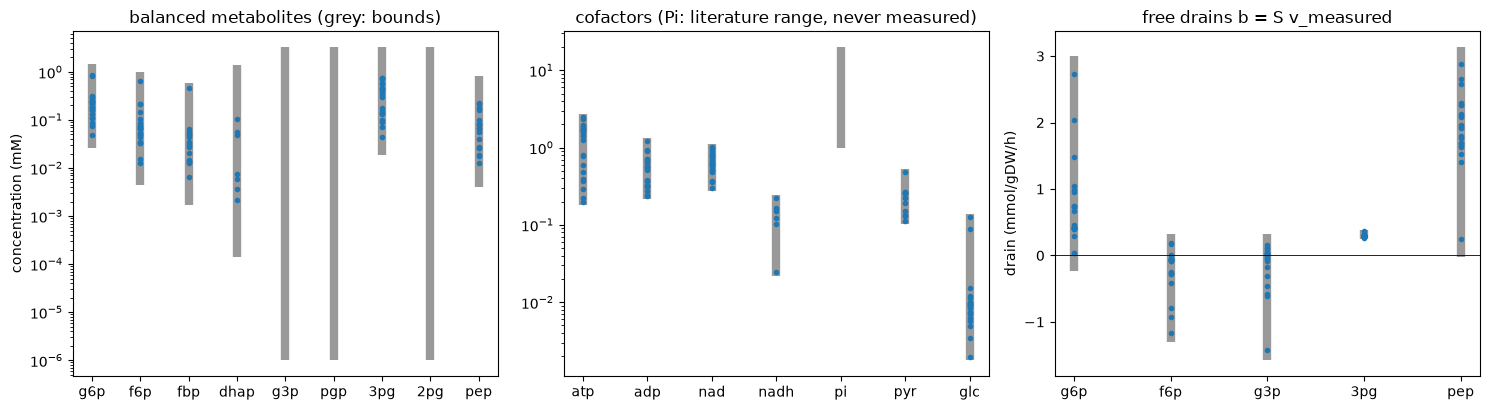

In [12]:
# check that the measured values are inside the bounds
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ax_x, ax_u, ax_b = axes

# balanced metabolites: boxes and the measured values
for i, k in enumerate(BALANCED_KEYS):
    ax_x.plot([i, i], x_bounds[k], color="0.6", lw=6, solid_capstyle="butt")
    vals = bal_df.loc[k].astype(float).dropna() if k in bal_df.index else pd.Series(dtype=float)
    ax_x.plot(np.full(len(vals), i), vals, "o", ms=3, color="tab:blue")

ax_x.set_yscale("log")
ax_x.set_xticks(range(len(BALANCED_KEYS)))
ax_x.set_xticklabels([k[2:] for k in BALANCED_KEYS])
ax_x.set_ylabel("concentration (mM)")
ax_x.set_title("balanced metabolites (grey: bounds)")

# cofactors
for i, k in enumerate(IMBALANCED_KEYS):
    ax_u.plot([i, i], u_bounds[k], color="0.6", lw=6, solid_capstyle="butt")
    vals = imb_df.loc[k].astype(float).dropna() if k in imb_df.index else pd.Series(dtype=float)
    vals = vals[vals > 0]
    ax_u.plot(np.full(len(vals), i), vals, "o", ms=3, color="tab:blue")

ax_u.set_yscale("log")
ax_u.set_xticks(range(len(IMBALANCED_KEYS)))
ax_u.set_xticklabels([k[2:] for k in IMBALANCED_KEYS])
ax_u.set_title("cofactors (Pi: literature range, never measured)")

# free drains
for i, k in enumerate(FREE_DRAIN_KEYS):
    ax_b.plot([i, i], drain_bounds[k], color="0.6", lw=6, solid_capstyle="butt")
    vals = needs_df.loc[k].astype(float)
    ax_b.plot(np.full(len(vals), i), vals, "o", ms=3, color="tab:blue")

ax_b.axhline(0, color="k", lw=0.6)
ax_b.set_xticks(range(len(FREE_DRAIN_KEYS)))
ax_b.set_xticklabels([k[2:] for k in FREE_DRAIN_KEYS])
ax_b.set_ylabel("drain (mmol/gDW/h)")
ax_b.set_title("free drains b = S v_measured")

fig.tight_layout()
plt.show()

## 7. The settings CSV files

All numbers that steer the pipeline are CSV files in `settings/`; `src/settings.py` is the one reader. Edit the CSV, not the code; a copy of the settings of a run is stored in `<out>/settings_used/`.

* `method.csv`: the settings of the method (multistart size, structural and practical criteria, bootstrap and profile likelihood); `settings.default_params()` returns them as the dict `params` that every notebook shows before it runs;
* `bounds_rules.csv`: the data bounds of section 6;
* `theta_bounds.csv`: the parameter bounds;
* `protected_params.csv`: prefixes of parameters that are never fixed;
* `solver_options.csv`: the IPOPT options of a fit (`default`), of a fit that starts at a previous solution (`warm_start`, added to the default ones) and of the steady-state prediction of a held-out condition (`closure`).

In [13]:
for name in ("method.csv", "bounds_rules.csv", "protected_params.csv"):
    table = pd.read_csv(os.path.join(SETTINGS_DIR, name), dtype=str, keep_default_na=False)
    print("=== settings/%s" % name)
    display(table.set_index(table.columns[0]))

=== settings/method.csv


,value,type,description
name,,,
n_starts,50,int,stage 0: random starts of the multistart (all parameters free; log-uniform in the para...
seed,0,int,seed of every random draw (multistart starts; structural realizations; bootstrap resam...
structural_q,10,int,structural identifiability: number of random parameter vectors (Stigter and Molenaar 2...
structural_tol,1e-10,float,structural identifiability: a singular value below this fraction of the largest is a s...
rank_tol,1e-4,float,practical identifiability: a singular value of the weighted sensitivity matrix below t...
corr_threshold,0.9,float,practical identifiability: parameter pairs with |r| above this are correlated
lr_alpha,0.95,float,confidence level of the likelihood-ratio threshold (profile likelihood)
bootstrap_n,5000,int,number of case-bootstrap resamples (conditions drawn with replacement)
bootstrap_ci_ratio,10.0,float,bootstrap: a parameter is practically identifiable if the ratio of its 97.5 and 2.5 pe...


=== settings/bounds_rules.csv


,value,type,description
name,,,
n_std,3.0,float,balanced metabolites: bounds exp(mu +/- n_std * sigma) of ln C over the conditions (3 ...
cofactor_slack,0.1,float,cofactors: measured range widened by this fraction on each side
drain_widen,0.1,float,free drains: measured range widened by this fraction of its span on each side
floor,1e-06,float,smallest lower bound of a concentration (mM)
pi_lo,1.0,float,lower bound of C_pi (mM); Pi is not measured so a physiological range is used
pi_hi,20.0,float,upper bound of C_pi (mM)


=== settings/protected_params.csv


,description
prefix,
kcat_f_,parameters with this prefix are never fixed by the selection (forward kcats)


In [14]:
print("=== settings/solver_options.csv")
pd.read_csv(os.path.join(SETTINGS_DIR, "solver_options.csv"), dtype=str, keep_default_na=False).set_index(["set", "option"])

=== settings/solver_options.csv


value   type                                                                                description
set        option                                                                                                                                
default    print_level                        0    int                                                                 IPOPT options of every fit
           max_iter                        8000    int                                                                                           
           tol                            1e-06  float                                                                                           
           acceptable_tol                 1e-05  float                                                                                           
           mu_strategy                 adaptive    str                                                                                           
           bound_push                     1e-08  float                                                                                           
           bound_frac                     1e-08  float                                                                                           
           warm_start_init_point            yes    str                                                                                           
warm_start mu_strategy                 monotone    str  added to the default options when a fit starts at a previous solution (refits; profile...
           mu_init                        1e-09  float                                                                                           
           warm_start_bound_push          1e-09  float                                                                                           
           warm_start_mult_bound_push     1e-09  float                                                                                           
           warm_start_bound_frac          1e-09  float                                                                                           
closure    print_level                        0    int  IPOPT options of the CasADi steady-state solve that predicts a held-out condition (LOOCV)
           sb                               yes    str                                                                                           
           tol                            1e-06  float                                                                                           
           mu_strategy                 adaptive    str